# Intermediate Machine Learning: Assignment 3

**Deadline**

Assignment 3 is due Thursday, November 5 by 11:59pm. Late work will not be accepted as per the course policies (see the Syllabus and Course policies on Canvas).

Directly sharing answers is not okay, but discussing problems with the course staff or with other students is encouraged. All problems will be given full credit if a significant attempt is made at a solution, whether or not the solution is complete or fully correct. This policy is intended to allow students the freedom to get the most learning value out of the assignment, and to lower incentives to use AI. According to course policy any use of an AI system such as ChatGPT, Claude, or Copilot must be acknowledged.

You should start early so that you have time to get help if you're stuck. The drop-in office hours schedule can be found on Canvas. You can also post questions or start discussions on Ed Discussion. The assignment may look long at first glance, but the problems are broken up into steps that should help you to make steady progress.

**Submission**

Submit your assignment as a .pdf on Gradescope. You can access Gradescope through Canvas on the left-side of the class home page. The problems in each homework assignment are numbered. Note: When submitting on Gradescope, please select the correct pages of your pdf that correspond to each problem. This will allow graders to more easily find your complete solution to each problem.

To produce the .pdf, please do the following in order to preserve the cell structure of the notebook:

1. Go to "File" at the top-left of your Jupyter Notebook.
2. Under "Download as", select "HTML (.html)".
3. After the .html has downloaded, open it and then select "File" and "Print" (note you will not actually be printing).
4. From the print window, select the option to save as a pdf.

If you are working in Colab, you may find it helpful to use this [converter notebook](https://colab.research.google.com/github/YData123/sds365-fa26/blob/main/assignments/Convert_ipynb_to_HTML_in_Colab.ipynb).

**Topics**

 * Variational autoencoders (VAEs)
 * Undirected graphs
 * The graphical lasso

## Problem 0: The decoder's hidden assumption (5 points)

In Problem 1 you will train a variational autoencoder and derive its loss function, whose
reconstruction term is a sum of squared errors. Squared error is usually presented as an
optimization choice, but it is not only that: it is the negative log-likelihood of a particular
probability model for the image. That model makes specific claims about how a real face differs
from its reconstruction, and this short warm-up asks you to state those claims before you fit
anything.

This problem is entirely conceptual — there is no code to write and nothing to run, and you do
not need to have finished Problem 1 before doing it.

Using the notation of Problem 1, write $D = 45 \times 45 \times 3 = 6075$ for the number of
coordinates in one image and index them $x_1, \dots, x_D$, so that a single coordinate $x_i$ is
one color channel at one pixel location. Write $z$ for the latent vector and
$G(z) \in \mathbb{R}^{D}$ for the output of the decoder, which is itself an image.

### 0.1 The loss is a likelihood (2 points)

The reconstruction term in the VAE loss, which you will derive in 1.1, has the form
$$
\tfrac{1}{2}\,\big\| x - G(z) \big\|^2
\;=\;
\tfrac{1}{2} \sum_{i=1}^{D} \big( x_i - G(z)_i \big)^2 .
$$

Answer the following briefly — a few lines each, not a long derivation.

**(i)** Write down a density $p(x \mid z)$ whose negative log-likelihood equals this expression
up to a multiplicative constant and an additive constant that does not depend on $x$ or $z$.

**(ii)** For the distribution you wrote down, identify the **mean** and the **covariance**, and
say where the variance $\sigma^2$ shows up in the loss.

**(iii)** The covariance has the special form $\sigma^2 I$. This encodes **two** separate
assumptions about how a real image differs from its reconstruction: one from the fact that the
matrix is *diagonal*, and one from the fact that its diagonal is *constant*. State both, one
sentence each.

**0.1 (i)**

Let $X|Z \sim \mathrm{N} (G(z), \sigma^2 I_d)$, where $x \in \mathbb{R}^d$ and G(z) is a function of the latent variable z. Then, by the definition of the density of a joint normal distribution, we get"
$$-\text{log}[p(x | z)] = -\text{log} \big[ (2 \pi)^{\frac{d}{2}} \star |\sigma^2 I_d|^{-\frac{1}{2}} \star \text{exp}\big\{ -\frac{1}{2} (x - G(z))^T (\sigma^2 I_d)^{-1} (x - G(z)) \big\} \big]$$
$$\implies -\text{log}[p(x | z)] = \frac{d}{2} \text{log}(2\pi) + \frac{1}{2} \text{log}(|\sigma^2 I_d|) + \frac{1}{2 \sigma^2} (x - G(z))^T (I_d)^{-1} (x - G(z))$$

Now, note that $|\sigma^2 I_d| = (\sigma^2)^d$ and $(x - G(z))^T (I_d)^{-1} (x - G(z)) = (x - G(z))^T (x - G(z)) = ||x - G(z)||^2$. Thus, we get

$$-\text{log} [p(x|z)] = \frac{d}{2} \text{log}(2\pi) + \frac{d}{2} \text{log}(\sigma^2) + \frac{1}{2 \sigma^2}||x - G(z)||^2$$

**(ii)**

In the density I defined, $X|Z \sim \mathrm{N}(G(z), \sigma^2 I_d)$, the mean $\mathbb{E}(X|Z = z)$ is $G(z)$ and covariance is $\sigma^2 I_d$. The variance $\sigma^2$ shows up because we define each $x_i$ as $x_i = G_i(z) + \epsilon_i$ where $\epsilon_i \sim \mathrm{N}(0, \sigma^2)$.

**(iii)**
The covariance has the special form $\sigma^2 I_d$. Thus, we can say:
- Since the covariance matrix is diagonal, each pixel is conditionally independent of each other, i.e. $\text{Cov}(x_i, x_j | Z = z) = 0$ where $i \neq j$.
- Since the diagonal is constant, we can assume that the noise associated with each pixel is independent and identically distributed conditional on Z, that is, each $\epsilon_i \sim \mathrm{N}(0, \sigma^2)$.

### 0.2 What the decoder says about pixels (3 points)

**(i)** Using your answer to 0.1, show that the density factorizes over the $D$ coordinates,
$$
p(x \mid z) \;=\; \prod_{i=1}^{D} p(x_i \mid z),
$$
and state the conditional independence relation this gives for two distinct coordinates
$x_i$ and $x_j$.

**(ii)** Describe — or sketch — the **generative** graphical model implied by this factorization,
in which $z$ is a shared parent of all $D$ coordinates:
$$
z \to x_1, \quad z \to x_2, \quad \ldots, \quad z \to x_D .
$$
Which edges are present, and what is the significance of there being no direct pixel-to-pixel
edges once $z$ is given? A sketch with a handful of $x_i$ nodes is enough — you do not need to
draw all 6075.

**(iii)** Explain why your answer to (i) does **not** say that $x_i$ and $x_j$ are *marginally*
independent. Your explanation should refer to
$$
p(x) \;=\; \int p(x \mid z)\, p(z)\, dz
$$
and should say what goes wrong if one tries to move the product over $i$ outside the integral.
Close with one sentence on what samples from the VAE would look like if the pixels really were
marginally independent.

*Note.* Problem 2 of this assignment draws the same distinction in a different setting: there
you will show that $\Omega_{ij} = 0$ if and only if $X_i \perp X_j \mid X_{-(i,j)}$, again a
statement about *conditional* independence, holding everything else fixed. The same distinction
is at work here, with $z$ in the role of the variables being conditioned on.

**0.2 (i)**

We have $X|Z \sim \mathrm{N}(0, \sigma^2 I_d)$ and $\text{Cov}(x_i, x_j|Z = z) = 0$ where $i \neq j$. Thus, we get
$$p(x|z) = p(x_1, x_2, \dots, x_D|z)$$
By conditional independence, we get
$$p(x|z) = p(x_1|z) p(x_2|z) \cdots p(x_D|z)$$
$$\implies p(x|z) = \prod_{i = 1}^D p(x_i|z)$$

This means that once the latent variable $Z$ is known, information about any one pixel $x_i$ does not give us any information about another pixel $x_j$.

**(iii)**
We have
$$p(x) = \int p(x|z) p(z) dz$$
From the above definintion, we get
$$p(x) = \int p(z) \prod_{i = 1}^D p(x_i|Z) dz$$
$$\implies p(x) = \int p(z) \prod_{i = 1}^D \frac{1}{\sqrt{2 \pi \sigma^2}} \text{exp}\big\{-\frac{(x_i - G_i(z))^2}{2 \sigma^2} \big\} dz$$

Notice that the product is a function of z and thus, cannot be taken outside the integral. Thus, the definition of the conditional density does not imply marginal independence.

If the pixels from the VAE were truly marginally independent, then images would have no cohesion since neighboring pixels would be uncorrelated.

## Problem 1: Face time (35 points)

In this problem, we will implement a "shoestring" version of [this amazing fake face generator](https://www.nytimes.com/interactive/2020/11/21/science/artificial-intelligence-fake-people-faces.html), using a variational autoencoder (VAE). Building a generator like the one featured in the article can take a tremendous amount of computational resources, time, and parameter tuning. In this problem we will build a basic version to illustrate the main concepts, and help you to become more famililar with VAEs.  Here is an outline of the process that we'll step you through:

### Problem outline:

* Load data
* Create face groups based on attributes
* Construct the VAE
* Define the loss function and train the VAE (Problem 1.1)
* Encode and reconstruct faces (Problem 1.2)
* Visualize the latent space (Problem 1.3)
* Morph between faces (Problem 1.4)
* Shift attributes of faces (Problem 1.5)
* Generate new faces (Problem 1.6)
* Analyze the effect of the scaling factor in the loss function (Problem 1.7, optional)

In the next cell we load the packages that we'll need. All of them are preinstalled on Google Colab. If you are working locally and don't have one or more of these, you can install them with `!pip install <package_name>` in the cell, or outside the notebook
with `conda install -c conda-forge <package_name>`.

This problem uses [PyTorch](https://pytorch.org/). Training is much faster on a GPU: on Colab, choose *Runtime → Change runtime type → T4 GPU* before running the notebook. The code also runs on a CPU (or on the GPU of an Apple Silicon Mac), just more slowly.

In [2]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import os
import glob
import urllib.request
import zipfile
import pandas as pd
import random
import numpy as np
import imageio.v2 as imageio
from tqdm import tqdm
from PIL import Image
from sklearn.model_selection import train_test_split
from scipy.stats import norm
import torch
from torch import nn

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Using device:", device)

Using device: cuda


### Loading the data

[Labeled Faces in the Wild](http://vis-www.cs.umass.edu/lfw/) (LFW) is a database of face photographs. The images are placed in the folder lfw-deepfunneled. lfw_attributes.txt is a document including a set of attributes associated for each image, such as 'Male', 'Smile', 'Bold', etc. All the features are numerical and large positive values indicate that the keywords well describe the photo; large negative values indicate that the keywords don't fit the photo.

For this problem, we will keep only the middle parts of the photos to avoid complex backgrounds.

The data is available from the cloud at these URLs:

https://sds365.s3.amazonaws.com/lfw/lfw-deepfunneled.zip
<br>
https://sds365.s3.amazonaws.com/lfw/lfw_attributes.txt

The next cell downloads and unzips the data (about 130 MB) into a folder `lfw` next to this notebook, unless it is already there. On Colab this folder is `/content/lfw`, and it is deleted when the runtime is recycled, so the cell will download the data again in a new session. If you have already downloaded the data elsewhere, set `DATA_DIR` to the folder that contains `lfw-deepfunneled` and `lfw_attributes.txt`.

Run all the cells in this section to load the data.

In [3]:
# Change DATA_DIR if you keep the data somewhere else
DATA_DIR = "lfw"
DATASET_PATH = os.path.join(DATA_DIR, "lfw-deepfunneled")
ATTRIBUTES_PATH = os.path.join(DATA_DIR, "lfw_attributes.txt")
DATA_URL = "https://sds365.s3.amazonaws.com/lfw/"

os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(ATTRIBUTES_PATH):
    urllib.request.urlretrieve(DATA_URL + "lfw_attributes.txt", ATTRIBUTES_PATH)
if not os.path.isdir(DATASET_PATH):
    zip_path = os.path.join(DATA_DIR, "lfw-deepfunneled.zip")
    urllib.request.urlretrieve(DATA_URL + "lfw-deepfunneled.zip", zip_path)
    with zipfile.ZipFile(zip_path) as zf:
        # skip the __MACOSX metadata folder that is also in the zip file
        zf.extractall(DATA_DIR, members=[m for m in zf.namelist() if m.startswith("lfw-deepfunneled/")])
    os.remove(zip_path)
print("Number of images:", len(glob.glob(os.path.join(DATASET_PATH, "*", "*.jpg"))))

Number of images: 13233


In [4]:

# Make sure the above path is correct before running this cell
dataset = []
for path in glob.iglob(os.path.join(DATASET_PATH, "**", "*.jpg")):
    person = path.split("/")[-2]
    dataset.append({"person":person, "path": path})

dataset = pd.DataFrame(dataset)
dataset = dataset.groupby("person").filter(lambda x: len(x) < 100 )
dataset.head(10)

,person,path
0,Juan_Francisco_Palencia,lfw/lfw-deepfunneled/Juan_Francisco_Palencia/J...
1,Billy_Beane,lfw/lfw-deepfunneled/Billy_Beane/Billy_Beane_0...
2,Marina_Kuptsova,lfw/lfw-deepfunneled/Marina_Kuptsova/Marina_Ku...
3,Andrew_Weissmann,lfw/lfw-deepfunneled/Andrew_Weissmann/Andrew_W...
4,Andrew_Weissmann,lfw/lfw-deepfunneled/Andrew_Weissmann/Andrew_W...
5,Andrew_Weissmann,lfw/lfw-deepfunneled/Andrew_Weissmann/Andrew_W...
6,Imam_Samudra,lfw/lfw-deepfunneled/Imam_Samudra/Imam_Samudra...
7,Malcolm_Jamal_Warner,lfw/lfw-deepfunneled/Malcolm_Jamal_Warner/Malc...
8,Dennis_Powell,lfw/lfw-deepfunneled/Dennis_Powell/Dennis_Powe...
9,Dennis_Powell,lfw/lfw-deepfunneled/Dennis_Powell/Dennis_Powe...


The following cell will display some sample images

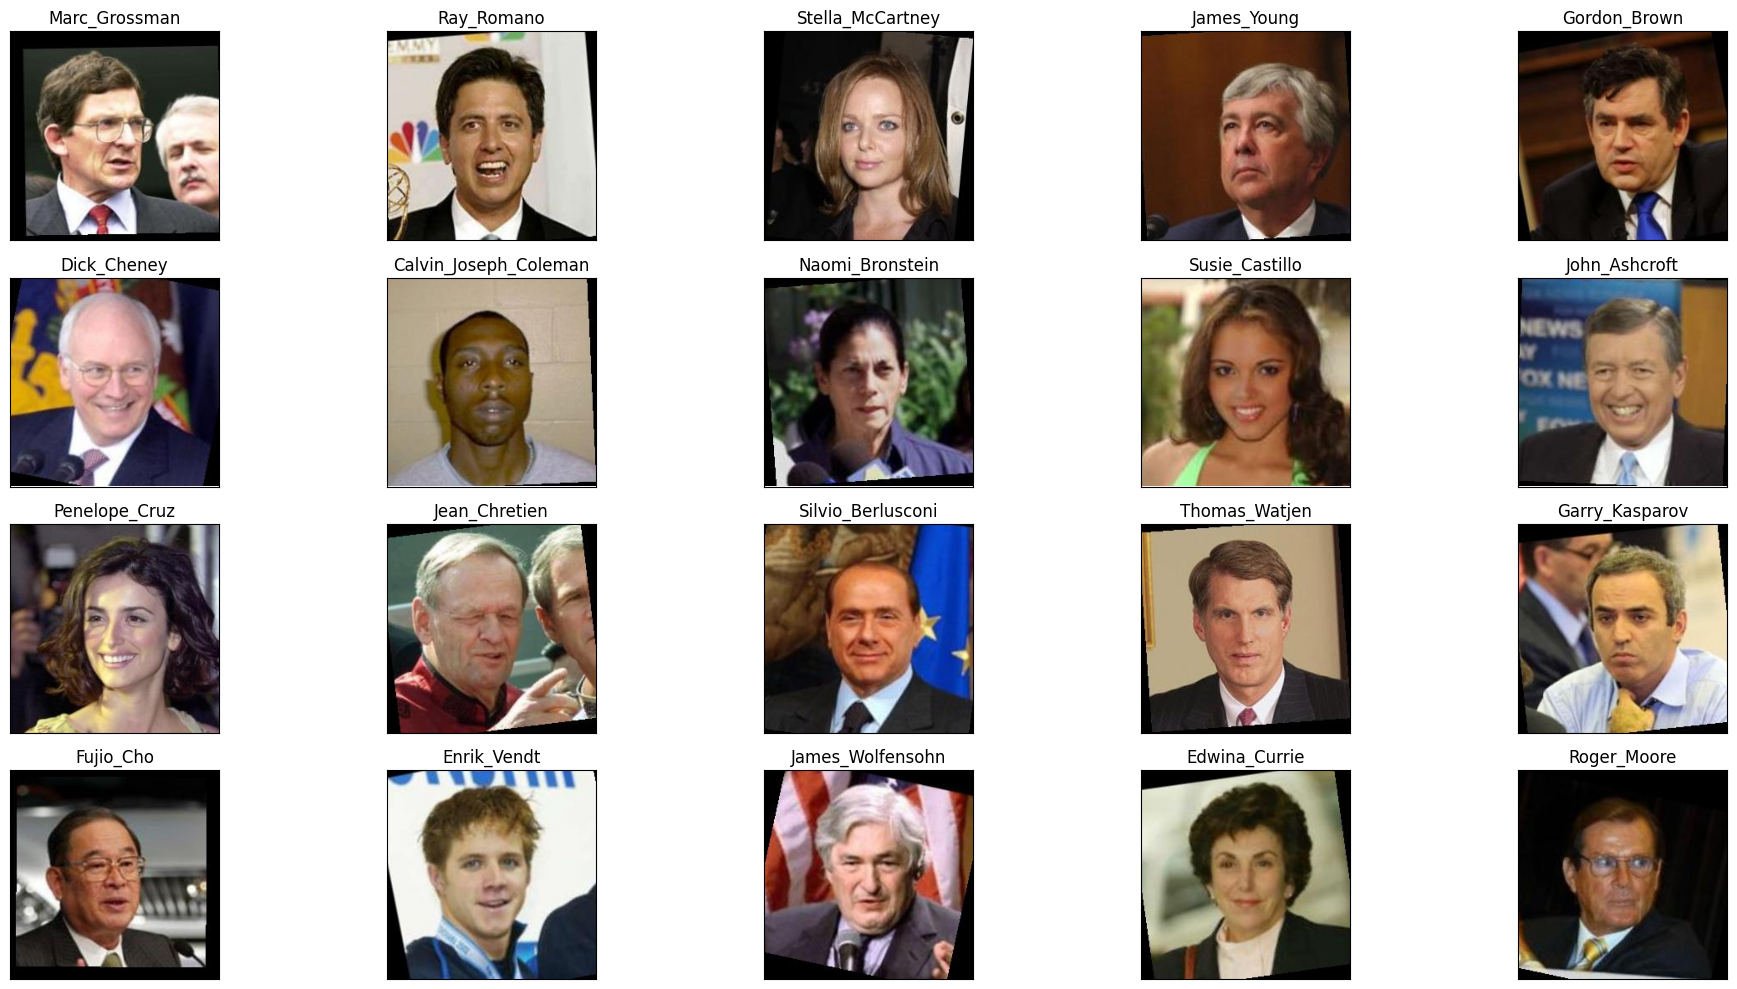

In [5]:
sampled_id = []

plt.figure(figsize=(20,10))
for i in range(20):
    idx = random.randrange(len(dataset))
    img = plt.imread(dataset.path.iloc[idx])
    plt.subplot(4, 5, i+1)
    plt.imshow(img)
    plt.title(dataset.person.iloc[idx])
    plt.xticks([])
    plt.yticks([])
    sampled_id.append(idx)
plt.tight_layout()
plt.show()

The following cell shows the images with some of the background removed.

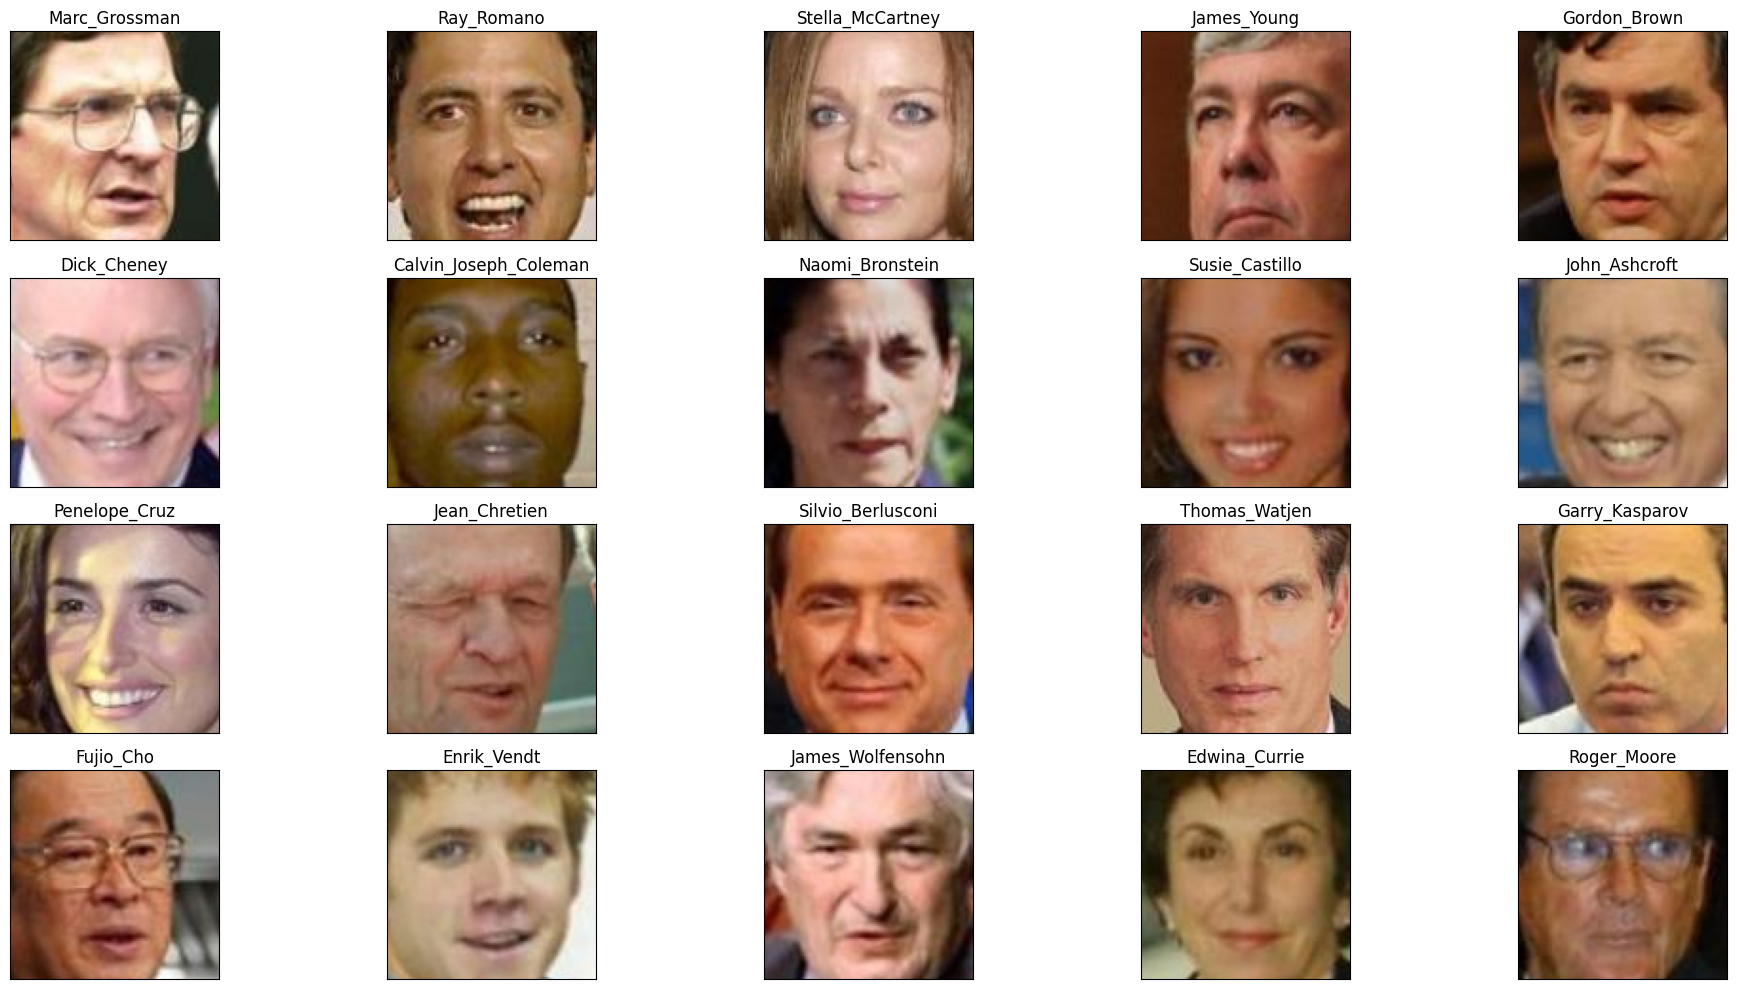

In [6]:
dx=70
dy=70

plt.figure(figsize=(20,10))
for i in range(20):
    idx = sampled_id[i]
    img = plt.imread(dataset.path.iloc[idx])
    plt.subplot(4, 5, i+1)
    plt.imshow(img[dy:-dy,dx:-dx])
    plt.title(dataset.person.iloc[idx])
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()

The following function crops the images to 45x45 pixels, which is what we will use in this problem.

In [7]:
def fetch_dataset(dx=70, dy=70, dimx=45, dimy=45):

    df_attrs = pd.read_csv(ATTRIBUTES_PATH, sep='\t', skiprows=1,)
    df_attrs = pd.DataFrame(df_attrs.iloc[:,:-1].values, columns = df_attrs.columns[1:])

    photo_ids = []
    for dirpath, dirnames, filenames in os.walk(DATASET_PATH):
        for fname in filenames:
            if fname.endswith(".jpg"):
                fpath = os.path.join(dirpath,fname)
                photo_id = fname[:-4].replace('_',' ').split()
                person_id = ' '.join(photo_id[:-1])
                photo_number = int(photo_id[-1])
                photo_ids.append({'person':person_id,'imagenum':photo_number,'photo_path':fpath})

    photo_ids = pd.DataFrame(photo_ids)
    df = pd.merge(df_attrs,photo_ids,on=('person','imagenum'))

    assert len(df)==len(df_attrs),"lost some data when merging dataframes"

    all_photos = df['photo_path'].apply(imageio.imread)\
                                .apply(lambda img:img[dy:-dy,dx:-dx])\
                                .apply(lambda img: np.array(Image.fromarray(img).resize([dimx,dimy])) )

    all_photos = np.stack(all_photos.values).astype('uint8')
    all_attrs = df.drop(["photo_path","person","imagenum"],axis=1)

    return all_photos,all_attrs

The variable `data` has all the face images and the variable `attrs` has all the attributes. The 8-bit RGB values are converted to values between 0 and 1 for modeling and plotting purposes.

In [8]:
data, attrs = fetch_dataset()
data = np.array(data / 255, dtype='float32')

### Create Face Groups

We can now create groups of faces, by selecting the faces having the highest or lowest scores for each of the attributes. Run all the cells in this section to create and plot some face groups.

In [9]:
def plot_gallery(images, h, w, n_row=3, n_col=6, with_title=False, titles=[]):
    plt.figure(figsize=(1.75 * n_col, 2 * n_row))
    plt.subplots_adjust(bottom=0, left=.01, right=.99, top=.90, hspace=.35)
    for i in range(n_row * n_col):
        plt.subplot(n_row, n_col, i + 1)
        try:
            plt.imshow(images[i].reshape((h, w, 3)), cmap=plt.cm.gray, vmin=-1, vmax=1, interpolation='nearest')
            if with_title:
                plt.title(titles[i])
            plt.xticks(())
            plt.yticks(())
        except:
            pass

In [10]:
IMAGE_H = data.shape[1]
IMAGE_W = data.shape[2]
N_CHANNELS = 3

In [11]:
smile_ids = attrs['Smiling'].sort_values(ascending=False).head(36).index.values
smile_data = data[smile_ids]

no_smile_ids = attrs['Smiling'].sort_values(ascending=True).head(36).index.values
no_smile_data = data[no_smile_ids]

eyeglasses_ids = attrs['Eyeglasses'].sort_values(ascending=False).head(36).index.values
eyeglasses_data = data[eyeglasses_ids]

sunglasses_ids = attrs['Sunglasses'].sort_values(ascending=False).head(36).index.values
sunglasses_data = data[sunglasses_ids]

no_sunglasses_ids = attrs['Sunglasses'].sort_values(ascending=True).head(36).index.values
no_sunglasses_data = data[no_sunglasses_ids]

mustache_ids = attrs['Mustache'].sort_values(ascending=False).head(36).index.values
mustache_data = data[mustache_ids]

male_ids = attrs['Male'].sort_values(ascending=False).head(36).index.values
male_data = data[male_ids]

female_ids = attrs['Male'].sort_values(ascending=True).head(36).index.values
female_data = data[female_ids]

eyeclosed_ids = attrs['Eyes Open'].sort_values(ascending=True).head(36).index.values
eyeclosed_data = data[eyeclosed_ids]

mouthopen_ids = attrs['Mouth Wide Open'].sort_values(ascending=False).head(36).index.values
mouthopen_data = data[mouthopen_ids]

makeup_ids = attrs['Heavy Makeup'].sort_values(ascending=False).head(36).index.values
makeup_data = data[makeup_ids]

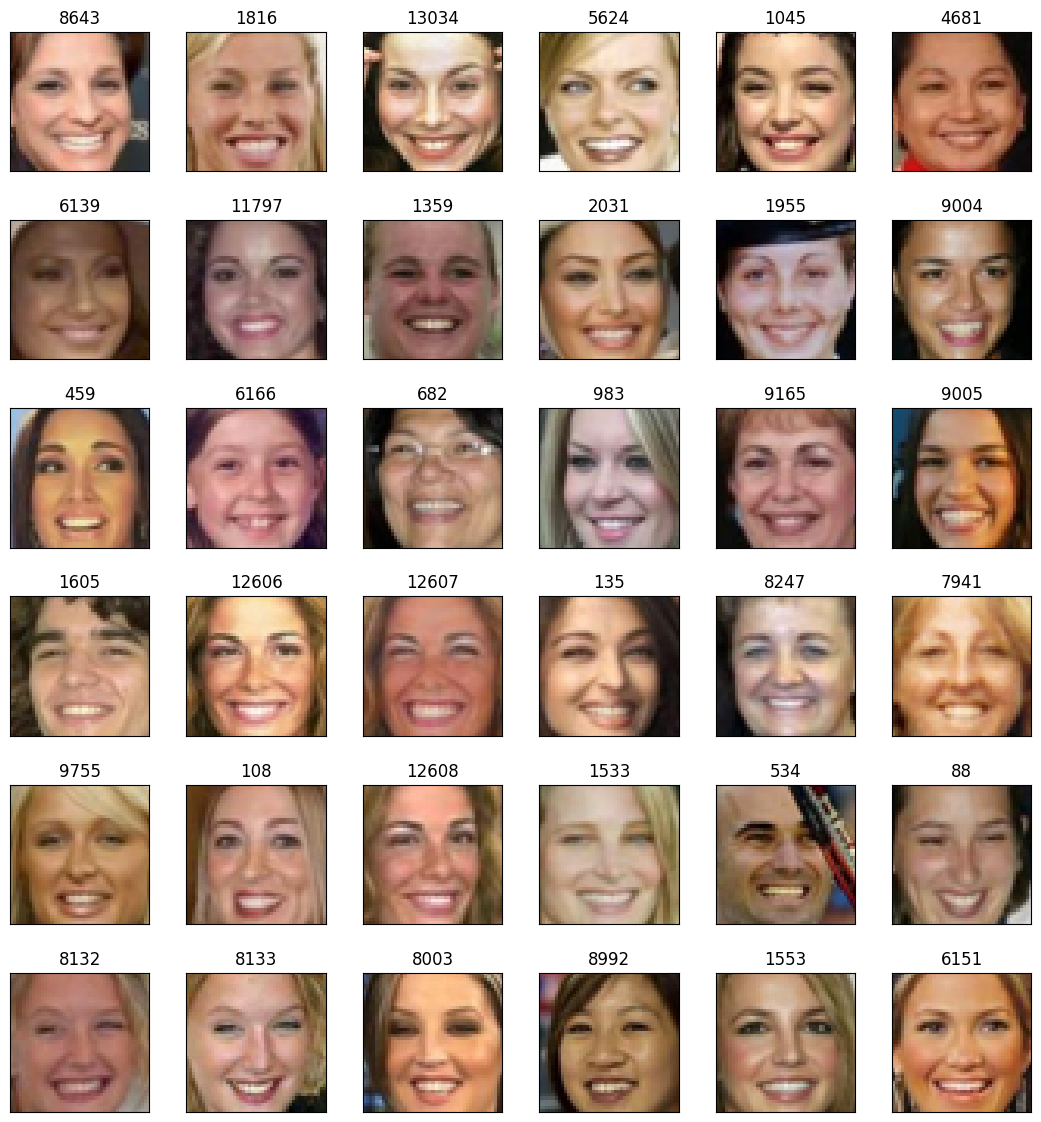

In [12]:
plot_gallery(smile_data, IMAGE_H, IMAGE_W, n_row=6, n_col=6, with_title=True, titles=smile_ids)

In [ ]:
plot_gallery(no_smile_data, IMAGE_H, IMAGE_W, n_row=6, n_col=6, with_title=True, titles=no_smile_ids)

In [ ]:
plot_gallery(eyeglasses_data, IMAGE_H, IMAGE_W, n_row=6, n_col=6, with_title=True, titles=eyeglasses_ids)

In [ ]:
plot_gallery(sunglasses_data, IMAGE_H, IMAGE_W, n_row=6, n_col=6, with_title=True, titles=sunglasses_ids)

In [ ]:
plot_gallery(mustache_data, IMAGE_H, IMAGE_W, n_row=6, n_col=6, with_title=True, titles=mustache_ids)

In [ ]:
plot_gallery(male_data, IMAGE_H, IMAGE_W, n_row=6, n_col=6, with_title=True, titles=male_ids)

In [ ]:
plot_gallery(female_data, IMAGE_H, IMAGE_W, n_row=6, n_col=6, with_title=True, titles=female_ids)

In [ ]:
plot_gallery(eyeclosed_data, IMAGE_H, IMAGE_W, n_row=6, n_col=6, with_title=True, titles=eyeclosed_ids)

In [ ]:
plot_gallery(mouthopen_data, IMAGE_H, IMAGE_W, n_row=6, n_col=6, with_title=True, titles=mouthopen_ids)

In [ ]:
plot_gallery(makeup_data, IMAGE_H, IMAGE_W, n_row=6, n_col=6, with_title=True, titles=makeup_ids)

### Constructing the encoder

Recall that the encoder part of the VAE architecture maps a data point to a variational mean and (log) variance. The mean is a point in the latent space.

A note on conventions: the images in `data` are stored as arrays of shape `(n, 45, 45, 3)` (height, width, color channel), which is what `plt.imshow` expects. PyTorch convolution layers expect the channel first, `(n, 3, 45, 45)`, so the encoder and decoder below permute the axes internally. You can always pass images to them in the `(n, 45, 45, 3)` layout.

In [13]:
LATENT_SPACE_SIZE = 100

The "reparameterization trick" draws samples from the variational distribution that are parameterized by the variational mean and variance, so that the parameters of the encoder network can be trained.

We also define a small helper class `Predictor`. It gives each of our networks a `predict` method that takes a NumPy array, runs the network on it in batches without tracking gradients, and returns a NumPy array. This is convenient for the analysis in Problems 1.2–1.6, where we only need the outputs of the trained networks.

In [14]:
def sample_latent_features(distribution_mean, distribution_log_variance):
    random = torch.randn_like(distribution_log_variance)
    return distribution_mean + torch.exp(0.5 * distribution_log_variance) * random


class Predictor(nn.Module):
    """Adds a NumPy-in, NumPy-out `predict` method to a network."""

    @torch.no_grad()
    def predict(self, inputs, batch_size=256):
        self.eval()
        model_device = next(self.parameters()).device
        outputs = []
        for start in range(0, len(inputs), batch_size):
            batch = torch.as_tensor(np.asarray(inputs[start:start + batch_size]),
                                    dtype=torch.float32, device=model_device)
            outputs.append(self.predict_step(batch).cpu().numpy())
        return np.concatenate(outputs)

In [15]:
class Encoder(Predictor):
    def __init__(self, latent_dim=LATENT_SPACE_SIZE):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, (5, 5)), nn.ReLU(), nn.MaxPool2d((2, 2)),    # 45x45 -> 41x41 -> 20x20
            nn.Conv2d(64, 64, (3, 3)), nn.ReLU(), nn.MaxPool2d((2, 2)),   # 20x20 -> 18x18 -> 9x9
            nn.Conv2d(64, 32, (3, 3)), nn.ReLU(), nn.MaxPool2d((2, 2)),   # 9x9 -> 7x7 -> 3x3
            nn.Flatten(),                                                 # 32 * 3 * 3 = 288
        )
        self.variational_mean = nn.Linear(32 * 3 * 3, latent_dim)
        self.variational_log_variance = nn.Linear(32 * 3 * 3, latent_dim)

    def forward(self, x):
        # x has shape (batch, 45, 45, 3); convolutions need (batch, 3, 45, 45)
        h = self.features(x.permute(0, 3, 1, 2))
        return self.variational_mean(h), self.variational_log_variance(h)

    def predict_step(self, x):
        # encoder_model.predict(images) returns a *sample* z from the variational distribution
        distribution_mean, distribution_log_variance = self(x)
        return sample_latent_features(distribution_mean, distribution_log_variance)


encoder_model = Encoder().to(device)
print(encoder_model)

Encoder(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
    (9): Flatten(start_dim=1, end_dim=-1)
  )
  (variational_mean): Linear(in_features=288, out_features=100, bias=True)
  (variational_log_variance): Linear(in_features=288, out_features=100, bias=True)
)


### Construct the decoder

The decoder network in the VAE architecture maps a latent vector to an image.
This is done with a series of transposed convolutional layers, since it must
map from low to high dimensions.


In [16]:
class Decoder(Predictor):
    def __init__(self, latent_dim=LATENT_SPACE_SIZE):
        super().__init__()
        self.net = nn.Sequential(
            nn.Unflatten(1, (latent_dim, 1, 1)),                                     # 1x1
            nn.ConvTranspose2d(latent_dim, 64, (3, 3)), nn.ReLU(), nn.Upsample(scale_factor=2),  # 3x3 -> 6x6
            nn.ConvTranspose2d(64, 32, (3, 3)), nn.ReLU(), nn.Upsample(scale_factor=2),  # 8x8 -> 16x16
            nn.ConvTranspose2d(32, 16, (5, 5)), nn.ReLU(), nn.Upsample(scale_factor=2),  # 20x20 -> 40x40
            nn.ConvTranspose2d(16, 3, (6, 6)), nn.ReLU(),                                # 45x45
        )

    def forward(self, z):
        # return images with shape (batch, 45, 45, 3), the same layout as `data`
        return self.net(z).permute(0, 2, 3, 1)

    def predict_step(self, z):
        return self(z)


decoder_model = Decoder().to(device)
print(decoder_model)

Decoder(
  (net): Sequential(
    (0): Unflatten(dim=1, unflattened_size=(100, 1, 1))
    (1): ConvTranspose2d(100, 64, kernel_size=(3, 3), stride=(1, 1))
    (2): ReLU()
    (3): Upsample(scale_factor=2.0, mode='nearest')
    (4): ConvTranspose2d(64, 32, kernel_size=(3, 3), stride=(1, 1))
    (5): ReLU()
    (6): Upsample(scale_factor=2.0, mode='nearest')
    (7): ConvTranspose2d(32, 16, kernel_size=(5, 5), stride=(1, 1))
    (8): ReLU()
    (9): Upsample(scale_factor=2.0, mode='nearest')
    (10): ConvTranspose2d(16, 3, kernel_size=(6, 6), stride=(1, 1))
    (11): ReLU()
  )
)


In [17]:
class VAE(Predictor):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, x):
        distribution_mean, distribution_log_variance = self.encoder(x)
        z = sample_latent_features(distribution_mean, distribution_log_variance)
        return self.decoder(z), distribution_mean, distribution_log_variance

    def predict_step(self, x):
        return self(x)[0]


autoencoder = VAE(encoder_model, decoder_model).to(device)

In [18]:
def get_loss(y_true, y_pred, distribution_mean, distribution_log_variance, factor):
    batch_size = y_true.shape[0]

    def get_reconstruction_loss(y_true, y_pred, factor, batch_size):
        reconstruction_loss = torch.square(y_true - y_pred)
        reconstruction_loss_batch = torch.sum(reconstruction_loss) / batch_size
        return 0.5 * reconstruction_loss_batch * factor

    def get_kl_loss(distribution_mean, distribution_log_variance, batch_size):
        kl_loss = 1 + distribution_log_variance - torch.square(distribution_mean) - torch.exp(distribution_log_variance)
        kl_loss_batch = torch.sum(kl_loss) / batch_size
        return kl_loss_batch * (-0.5)

    reconstruction_loss_batch = get_reconstruction_loss(y_true, y_pred, factor, batch_size)
    kl_loss_batch = get_kl_loss(distribution_mean, distribution_log_variance, batch_size)
    return reconstruction_loss_batch + kl_loss_batch

### 1.1 Deriving the loss function (5 points)

Derive the loss function defined in the cell above from the probability model perspective. You can ignore the scalar `factor` in your derivation. Show your work using either LaTeX or a picture of your written solution.

Hint: Think about how how the total loss is related to the ELBO.

In our VAE, let $Z$ be our latent variable and $Y$ be our observed data, where $Y \in \mathbb{R}^d$ and $Z \in \mathbb{R}^k$. Here, we assume a standard normal prior distribution of $Z$, i.e., $Z \sim \mathrm{N}(0, I_k)$.

Now, assuming we have a single layer MLP, we define our encoder and decoder as follows:
- Encoder: $Z|Y \sim \mathrm{N}(\mu_y, \sigma_y^2 I_k)$
- Decoder: $Y|Z \sim \mathrm{N}(G(z), \sigma^2 I_d)$

Notice that we approximate a posteior in our encoder as $Z|Y \sim \mathrm{N}(\mu_y, \sigma_y^2 I_k)$ and we define $y_i = G_i(z) + \epsilon_i$, where $\epsilon_i \sim \mathrm{N}(0, \sigma^2)$. Thus, we train both networks simultaneously to maximise the ELBO, which is equal to $\mathbb{E}_q \text{log}(p(Y|Z)) - D_{KL} (q(Z|Y) || p(Z))$, where the first term is the decoder loss and the second term is the encoder loss. Note that maximizing the ELBO is equivalent to minimizing the negative ELBO.

Now, focusing on the decoder loss, from the derivation in problem 0.1 part (i), we get:
$$-\text{log}(p(Y|Z = z)) = \frac{d}{2} \text{log}(2\pi) + \frac{d}{2} \text{log}(\sigma^2) + \frac{1}{2 \sigma^2}||y - G(z)||^2$$

Now, since we our sampling $Z$ from the variational distribution of $Y$, then by the law of large numbers, we can define expectation over $q(Z|Y)$ as:

$$-\mathbb{E}_q \text{log}(p(Y|Z)) = \frac{1}{N} \sum_{i = 1}^N \frac{d}{2} \text{log}(2\pi) + \frac{d}{2} \text{log}(\sigma^2) + \frac{1}{2 \sigma^2}||y - G(z_i)||^2$$

$$\implies \mathbb{E}_q \text{log}(p(Y|Z)) = \frac{d}{2} \text{log}(2\pi) + \frac{d}{2} \text{log}(\sigma^2) + \frac{1}{2N \sigma^2} \sum_{i = 1}^N ||y - G(z_i)||^2,$$
where $N$ is the batch size.

The following cells train the model. You can just run them. It may take a while to run on your laptop; on a Colab GPU it takes a few minutes. The function `train_vae` prints the average loss on the training and validation sets after each epoch.

In [20]:
X_train, X_val = train_test_split(data, test_size=0.2, random_state=365)

In [21]:
def train_vae(autoencoder, X_train, X_val, factor, epochs, batch_size=64, learning_rate=1e-3):
    optimizer = torch.optim.Adam(autoencoder.parameters(), lr=learning_rate)
    X_train_tensor = torch.as_tensor(X_train, device=device)
    X_val_tensor = torch.as_tensor(X_val, device=device)
    history = {"loss": [], "val_loss": []}

    for epoch in range(epochs):
        autoencoder.train()
        permutation = torch.randperm(len(X_train_tensor), device=device)
        train_loss = 0.0
        for start in range(0, len(X_train_tensor), batch_size):
            x = X_train_tensor[permutation[start:start + batch_size]]
            x_reconstructed, distribution_mean, distribution_log_variance = autoencoder(x)
            loss = get_loss(x, x_reconstructed, distribution_mean, distribution_log_variance, factor)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * len(x)

        autoencoder.eval()
        val_loss = 0.0
        with torch.no_grad():
            for start in range(0, len(X_val_tensor), batch_size):
                x = X_val_tensor[start:start + batch_size]
                x_reconstructed, distribution_mean, distribution_log_variance = autoencoder(x)
                val_loss += get_loss(x, x_reconstructed, distribution_mean, distribution_log_variance, factor).item() * len(x)

        history["loss"].append(train_loss / len(X_train_tensor))
        history["val_loss"].append(val_loss / len(X_val_tensor))
        print(f"Epoch {epoch + 1}/{epochs}  loss: {history['loss'][-1]:.2f}  val_loss: {history['val_loss'][-1]:.2f}")
    return history

In [ ]:
torch.manual_seed(365)
history = train_vae(autoencoder, X_train, X_val, factor=100, epochs=50, batch_size=64)

In [ ]:
# Save your trained model (for later use). The encoder and decoder are saved as part of the VAE.

# torch.save(autoencoder.state_dict(), "My_Trained_VAE.pt")

If you experience issues while training the model above or if the process is taking too long, you may also use our pre-trained VAE, which is available on Canvas as `Trained_VAE.pt`. (On Colab, upload it with the file browser on the left.) Loading it into `autoencoder` also loads the trained weights into `encoder_model` and `decoder_model`, since they are parts of the VAE.

No points will be taken off if you decide to use the pre-trained model, but we do recommend trying out the training process above. In case you encounter any issues when loading in the model, please post your questions on Ed discussion.

In [ ]:
# Load Pre-trained Model

# autoencoder.load_state_dict(torch.load("Trained_VAE.pt", map_location=device))

### 1.2 Reconstructing faces (3 points)

The following cell encodes and reconstructs 16 random faces from the validation set with the trained VAE. Run the cell and comment on the reconstructed faces. (3 points)
* Do the reconstructed faces resemble the original images? How are they similar/different?
* Are there any faces that are reconstructed better or worse than the others? Can you think of why?
* Comment on any other aspects of your findings that are interesting to you.

In [ ]:
sample_index = random.sample(range(1, len(X_val)), 16)

fig, axs = plt.subplots(4, 8)
fig.set_figheight(10)
fig.set_figwidth(15)

for i in range(4):
    for j in range(4):
        axs[i, 2*j].imshow(X_val[sample_index[4*i+j], :, :, :])
        axs[i, 2*j].axis('off')
        axs[i, 2*j+1].imshow(np.clip(autoencoder.predict(np.array([X_val[sample_index[4*i+j], :, :, :]]))[0],0,1))
        axs[i, 2*j+1].axis('off')

[Your markdown here]

### 1.3 Visualizing the latent space (10 points)

In `vae_demo` from class, the MNIST digits were generated from a two-dimensional latent space. In the current model, the latent space has more than two dimensions, so to visualize it we need to use a dimensionality reduction technique. (If you are not familiar with PCA, please refer to the material for Week 7 of [iML](https://ydata123.org/fa21/iml/calendar.html).)

In this problem, you will first implement the function `LatentSpace_2D`. (6 points)
1. Calculate the latent space encodings for two sets of faces that are different in one attribute, e.g. smile vs. no smile.
2. Use PCA to reduce the dimension of the latent space codes to two.
3. Visualize the latent space after dimensionality reduction with a scatter plot. Clearly color-code and label the two different groups.

Here is an example using smile_data and no_smile_data.
![Sample_1_3](https://raw.githubusercontent.com/YData123/sds365-sp22/main/assignments/assn3/Sample_1_3.png)

Visualize the latent space for at least three pairs of face groups including smile vs. no smile. Comment on how the scatter plots look.
* Are the two groups separable in the two-dimensional latent space? Is this what you expected? Why or why not? (2 points)
* How do the plots for the three different attributes differ from each other? (2 points)

To compute latent codes you can use `encoder_model.predict(images)`, which returns a sample $z$ from the variational distribution for each image, or call the encoder directly on a tensor to get the variational means and log variances, e.g. `encoder_model(torch.as_tensor(images, device=device))`. The same applies to 1.5.

In [ ]:
def LatentSpace_2D(encoder_model, data1, label1, data2, label2):
    # Your code here
    pass

In [ ]:
LatentSpace_2D(encoder_model, smile_data, 'Smile', no_smile_data, 'No smile')

In [ ]:
LatentSpace_2D(encoder_model,no_sunglasses_data,'No sunglasses',sunglasses_data,'Sunglasses')

In [ ]:
LatentSpace_2D(encoder_model,male_data,'Male',female_data,'Female')

[Your markdown here]

### 1.4 Morphing between faces (4 points)

Morph at least 5 pairs of faces with the function `morphBetweenImages` and comment on what you observe.
* Briefly explain how the morphing works. (2 points)
* Do the generated faces look like what you expected? Does any of the pairs work better than the others? If so, what kind of image pairs work better? (2 points)

In [ ]:
# Don't change the function
def morphBetweenImages(img1, img2, num_of_morphs):
    alpha = np.linspace(0,1,num_of_morphs)
    z1 = encoder_model.predict(np.array([img1]))
    z2 = encoder_model.predict(np.array([img2]))
    fig = plt.figure(figsize=(30,5))

    ax = fig.add_subplot(1, num_of_morphs+2, 1)
    ax.imshow(img1)
    ax.axis('off')
    ax.set_title(loc='center', label='original image 1',fontsize=10)

    for i in range(num_of_morphs):
        z = z1*(1-alpha[i]) + z2*alpha[i]
        new_img = decoder_model.predict(z)

        ax = fig.add_subplot(1, num_of_morphs+2, i+2)
        ax.imshow(np.clip(new_img.squeeze(),0,1))
        ax.axis('off')
        ax.set_title(loc='center', label='alpha={:.2f}'.format(alpha[i]))

    ax = fig.add_subplot(1, num_of_morphs+2, num_of_morphs+2)
    ax.imshow(img2)
    ax.axis('off')
    ax.set_title(loc='center', label='original image 2',fontsize=10)
    return

In [ ]:
sample_index = random.sample(range(1, len(data)), 2)
morphBetweenImages(data[sample_index[0]],data[sample_index[1]],10)

### 1.5 Attribute shift (10 points)

In 1.3, we've seen that faces with the same attributes form clusters in the latent space. In this problem, you will implement a function `AttributeShift` to change one attribute of the faces.

First implement the function `AttributeShift`. (5 points)
1. Calculate the latent space codes for two sets of faces that are different in one attribute, e.g. smile vs. no smile.
2. Calculate the mean latent space code for each group.
3. Get the attribute shifting vector by taking the difference between the two codes.
4. Perform attribute shift by adding the attribute shifting vector to the latent space code of the faces you want to modify.
5. Generate the image using the new latent space codes.

Here is a diagram demonstrating the shift in the latent space. Please note that the two-dimensional latent space is just for demonstration purpose. You should *not* use PCA in this problem. Instead, use the original latent space.
![Diagram_1_5](https://raw.githubusercontent.com/YData123/sds365-sp22/main/assignments/assn3/Diagram_1_5.png)

Perform attribute shift on at three attributes including smile. Comment on the faces with shifted attributes. (5 points)
* Do the generated faces look like what you expected? If not, can you think of some possible reasons?
* Do the faces with new attributes resemble the original faces? If not, can you think of some possible reasons?
* Which of the attribute shift is more successful? What are some possible reasons?
* Comment on any other aspects of your findings that are interesting to you.

In [ ]:
# Don't change this helper function!
def PlotAttributeShift(data2,pic_output):
    sample_index = random.sample(range(1, len(data2)), 16)

    fig, axs = plt.subplots(4, 8)
    fig.set_figheight(10)
    fig.set_figwidth(15)

    for i in range(4):
        for j in range(4):
            axs[i, 2*j].imshow(data2[sample_index[4*i+j], :, :, :])
            axs[i, 2*j].axis('off')
            axs[i, 2*j+1].imshow(np.clip(pic_output[sample_index[4*i+j]],0,1))
            axs[i, 2*j+1].axis('off')

In [ ]:
def AttributeShift(encoder_model,decoder_model,data1,data2):
    # Your code here
    return pic_output

In [ ]:
pic_output = AttributeShift(encoder_model,decoder_model,smile_data,no_smile_data)
PlotAttributeShift(no_smile_data,pic_output)

[Your markdown here]

### 1.6 Generating new faces (3 points)

Variational autoencoders can be used to generate new data; this is why they are generative models. We can sample new data points from the distribution in latent space and reconstruct new, fake faces based on them.

To draw a sample close to an existing sample in the latent space, we can add a scaled random sample from the normal distribution to the latent space code of an existing sample. The scalar, which we call the `noise_level` is a parameter that we can tune.

Run `GenerateFaces` with three different values of `noise_level` and comment on the generated faces. (3 points)
* Do the generated images look like faces?
* What happens when the new samples diverge more from the existing samples? What is a possible reason?

In [ ]:
def GenerateFaces(data, LATENT_SPACE_SIZE, noise_level):
    sample_index = random.sample(range(1, len(data)), 15)
    latent_space = noise_level*np.random.normal(size=(15,LATENT_SPACE_SIZE))+encoder_model.predict(data[sample_index])
    generated_image = decoder_model.predict(latent_space)
    fig = plt.figure(figsize=(15,10))
    for i in range(len(generated_image)):
        ax = fig.add_subplot(3, 5, i+1)
        ax.imshow(np.clip(generated_image[i, :,:,:],0,1))
        ax.axis('off')

In [ ]:
GenerateFaces(data,LATENT_SPACE_SIZE,0.1)

In [ ]:
GenerateFaces(data,LATENT_SPACE_SIZE,0.5)

In [ ]:
GenerateFaces(data,LATENT_SPACE_SIZE,1)

[Your markdown here]

### Optional: Changing the loss function (2 points extra credit)

The variable `factor` is a parameter of the loss function. In this optional problem, you will play with it and think about its effect on the performance of VAE.

Retrain the model with a smaller factor. Repeat 1.2, 1.6 (using `noise_level` = 1) and latent space visualization. Comment on how the reconstruction results, generated new faces and latent space distributions change. (2 points)
* Which model reconstructs the faces better?
* Do the generated faces look different?
* How do the latent variable distributions differ?
* Do the differences make sense? Can you explain what you observed?

For example, you can build a new model with `Encoder()`, `Decoder()` and `VAE(...)` as above and train it with `train_vae(..., factor=...)`. Remember that `GenerateFaces` and `morphBetweenImages` use the global variables `encoder_model` and `decoder_model`.

In [ ]:
# Your code here

[Your markdown here]

## Problem 2: Gaussian neighborhood regression (10 points)
In multivariate Gaussians, edges are about *direct* relationships after controlling for all other variables. The conditional law of a single coordinate $X_i$ given the rest $X_{-i}$ reveals which variables directly “enter” the model for $X_i$. Algebraically, this local behavior is encoded by the $i$th row/column of the precision matrix $\Omega=\Sigma^{-1}$.  Graphical Lasso estimates a sparse precision matrix $\widehat{\Omega}$ by maximizing the Gaussian log-likelihood with an $\ell_1$ penalty on off-diagonal entries. Zeros in $\widehat{\Omega}$ correspond to missing edges (conditional independences) in the learned graph.



Let $X=(X_1,\dots,X_p)^\top \sim \mathcal N_p(0,\Sigma)$, and write $\Omega=\Sigma^{-1}$. For $i\in\{1,\dots,p\}$, denote $-i=\{1,\dots,p\}\setminus\{i\}$.




### 2.1 Conditional law of one node.
Show that $X_i\mid X_{-i}$ is Gaussian with a linear mean in $X_{-i}$. Express the regression coefficients $\beta_{i\leftarrow -i}\in\mathbb{R}^{p-1}$ and the conditional variance $\sigma^2_{i\mid -i}$ in terms of $\Omega$.


*Hint.* You may *complete the square* on $x^\top\Omega x$, or use a *Schur complement* derivation. After permuting coordinates so that $i$ is first, partition
$$
\Sigma \;=\; \begin{bmatrix}
a & b^\top \\[4pt]
b & C
\end{bmatrix},
\quad
a=\Sigma_{ii}\in\mathbb{R},\; b=\Sigma_{-i,i}\in\mathbb{R}^{p-1},\; C=\Sigma_{-i,-i}\in\mathbb{R}^{(p-1)\times(p-1)}.
$$
**Schur complement.** If $C$ is invertible (it is, since $\Sigma\succ 0$), the Schur complement of $C$ in $\Sigma$ is
$$
S \;:=\; a - b^\top C^{-1} b .
$$
**Block inversion formula.** Then
$$
\Sigma^{-1}
=\begin{bmatrix}
S^{-1} & -\,S^{-1} b^\top C^{-1}\\[4pt]
-\,C^{-1} b S^{-1} & C^{-1} + C^{-1} b S^{-1} b^\top C^{-1}
\end{bmatrix}.
$$

[Your markdown here]


### 2.2 One neighbor at a time.
Fix $j\neq i$. First prove that the coefficient of $X_j$ in the mean of $X_i \mid X_{-i}$ equals zero if and only if $\Omega_{ij}=0$. Then deduce (Gaussian case) that
$$\Omega_{ij}=0 \quad\Longleftrightarrow\quad X_i\ \perp\ X_j\ \big|\ X_{-(i,j)}.$$


*Hint:* Use the result from 2.1. *“iff” ($\Longleftrightarrow$) means:* prove **both** directions (⇒ and ⇐).  


[Your markdown here]


### 2.3 Factorization and graph structure
Suppose every coefficient in the mean of $X_i\mid X_{-i}$ is zero (i.e., $\beta_{i\leftarrow -i}=0$). Show that the joint density factorizes as $p(x)=p(x_i)\,p(x_{-i})$. Briefly interpret the implication **for the graph structure**.

[Your markdown here]

## Problem 3: Taking stock (15 points)

A joint distribution of data has a natural graph associated with it. When the distribution is multivariate normal, this graph is encoded in the pattern of zeros and non-zeros in the inverse of the covariance matrix, also known as the "precision matrix."

In class we demonstrated the graphical lasso for estimating the graph on ETF data.
In this problem you will construct two different "portfolios" of stocks,
and run the graphical lasso to estimate a graph, commenting on your results.

All of the code you might need for this is contained in the demo.


## Data provided

As demonstrated in class, you will run on equities data downloaded from Yahoo Finance. Your job is to construct two “portfolios” of stocks, each with some organizing principle (e.g., sectors, regions, indices vs. equities). Each portfolio must contain **at least 20 stocks**. The page https://en.wikipedia.org/wiki/List_of_S%26P_500_companies has GICS sectors, which you may find useful for the glasso problem.


You are provided two CSV files containing stock prices **since 2021-09-10 (post-COVID start)**:
- [full_stock_daily.csv](https://raw.githubusercontent.com/YData123/sds365-fa26/main/assignments/assn3/full_stock_daily.csv) (rows = dates, columns = **ticker** symbols; daily close)
- [full_stock_weekly.csv](https://raw.githubusercontent.com/YData123/sds365-fa26/main/assignments/assn3/full_stock_weekly.csv) (rows = dates, columns = **ticker** symbols; weekly close = last available trading day of the week)

> **Note on NAs.** Some symbols begin trading after 2021-09-10, so their early entries will be `NA`. Handle missingness during preprocessing (see checklist below).  

> You can look up prices by ticker and date directly from these CSVs. If a needed symbol is **not** in the CSVs, use the provided **R file** `stock_price_from_yahoo_finance.r` to fetch it (via BatchGetSymbols) and merge it into your working data.

**Preprocessing checklist (concise):**
- Select your symbols; **align dates** across symbols.
- For the analysis window you choose, **filter** symbols with poor coverage (e.g., keep ≥90–95% non-missing).
- Build a **complete-cases** matrix for Graphical Lasso (no NAs across chosen symbols/dates).

### Analyzing  your portfolios

Your task is to analyze each porfolio using the graphical lasso, and comment on your findings.
Here are the types of questions you should address:

* How did you choose the portolio? How did you choose the date range and frequency (daily, weekly, etc.)? Remember, each of the portfolios must contain at least 20 stocks, and be organized in some reasonable way.

* Display the graph obtained with the graphical lasso, using networkx. How did you choose the regularization level? Does the structure of the graph make sense? Is it sensitive to the choice of regularization level? Is this the structure you expected to see when you designed the portfolio? Why or why not?

* What are some of the conditional independence assumptions implied by the graph? Are some parts of the graph more densely connected than others? Why?


